# Two particles in one image

### What you will learn

1. what an image holding two real particles looks like, and what the engine reports for it;
2. how the reported size changes as the two drops move apart;
3. what the package's grouping tool says about the same image, and what it does not do;
4. what is known about how often this happens;
5. how to test your own images, and what is on by default.

### What data this uses

None from disk. Every image is *synthetic*: two discs of 11 pixels diameter, level with each
other in time, on a 128-diode array. Pixel size is assumed to be 10 µm.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page), [12_particle_gallery](12_particle_gallery.ipynb) (What is not a particle: a gallery of optical array probe artifacts), [14_stray_pixels](14_stray_pixels.ipynb) (Stray pixels and images in pieces). **Related:** [05_images_in_pieces](05_images_in_pieces.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The next cell checks that the notebook runs from the repository root, where the paths below start.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys

if "examples" not in sys.path:  # shared helper modules (_style.py) sit in examples/
    sys.path.insert(0, "examples")

## 1. What it looks like

An image is a boolean array, `True` where a diode was in shadow; time (slices) runs along the
horizontal axis and the diodes along the vertical axis, diode 1 at the top. Two drops that cross the sample volume almost together, at different places along
the array, can share the same slices. Nothing in the image says there were two events: the
shadows are two blobs. Below, the second drop is moved away from the first; the label is
the distance between the two centres in diodes.

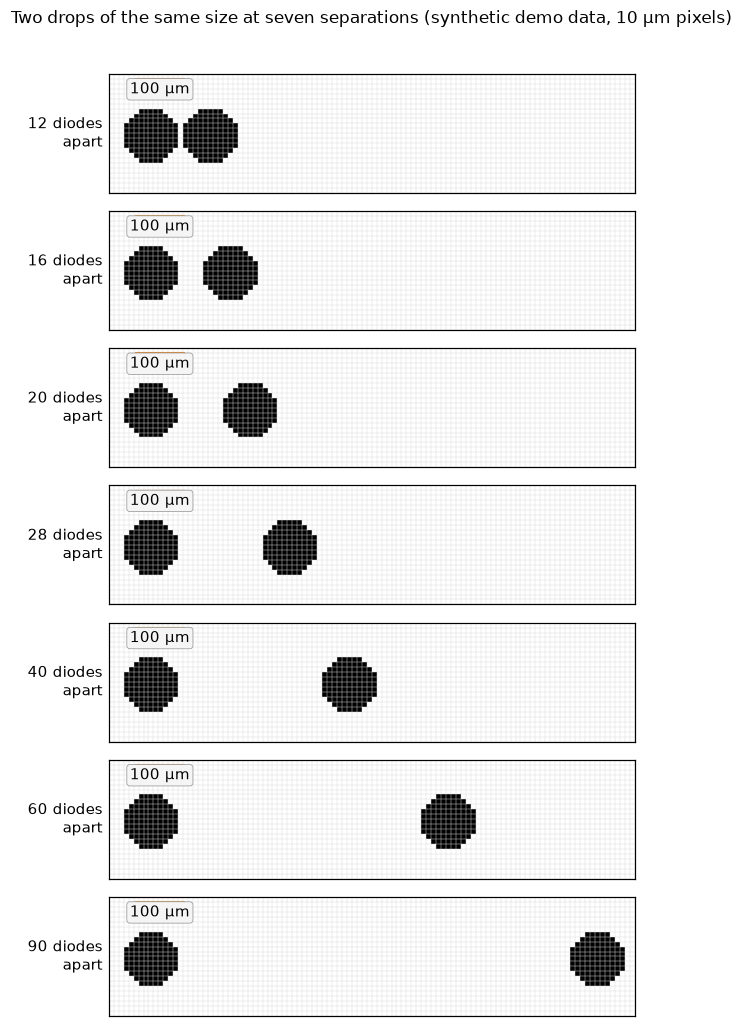

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import _style                  # house style: _style.py sits beside this notebook
_style.apply()

NDIODE, NSLICE, D = 128, 24, 11
PX_UM = 10.0
ii, jj = np.mgrid[0:NSLICE, 0:NDIODE]

def disc(row, col, diameter=D):
    return (ii - row) ** 2 + (jj - col) ** 2 <= (diameter / 2) ** 2

def pair(sep, col0=8):
    return disc(NSLICE // 2, col0) | disc(NSLICE // 2, col0 + sep)

seps = [12, 16, 20, 28, 40, 60, 90]
fig, axs = plt.subplots(len(seps), 1, figsize=(9, 9.5))
for ax, s in zip(axs, seps):
    # one strip per row: diodes run left to right, time runs downward
    _style.pixels(ax, pair(s)[:, :106], um_per_px=PX_UM, bar_top=True)
    ax.set_ylabel(f"{s} diodes\napart", fontsize=10, rotation=0, ha="right", va="center")
fig.suptitle("Two drops of the same size at seven separations (synthetic demo data, 10 µm pixels)",
             fontsize=11)
fig.tight_layout(rect=(0.0, 0.0, 1, 0.97))
fig.savefig("examples/figures/two_images.png", dpi=110, bbox_inches="tight")
plt.show()

*Figure 1. Two synthetic drops of the same size, 11 diodes across, imaged at seven separations. Each row is one image: diodes run left to right, time runs downward, and each square is one 10 µm pixel.*

## 2. What the engine does with it

The cause, as far as it is known:
UIOOPS's `imgProc_sm.m` closes a particle's frame at a boundary near `:250`, and two events not
separated by a fully blank slice were written to the product as one oversized particle. The
behaviour was seen on a real image; it is **not traced to a line** and the
suggested edit (require a minimum run of blank slices between events) is untested. A pair like
the ones above is therefore not split by the engine: the measurement block receives one image.

The cell runs the engine's own routines on it. Size is the smallest enclosing circle
(`cgal_min_r_v35`, as called by `measure_record`, `src/arrayprobe_uiops/measure.py`), a diameter
in pixels, and the reject code comes from `calculate_reject_unified`. For the pieces it also runs
the triage tool `arrayprobe.triage_context.piece_groups`, with `gap=0` (plain 8-connectivity) and
`gap=8` (`PIECE_GAP_DIODES`, the triage page's setting), and the stray-pixel correction
`remove_stray_pixels`, which is on by default in the engine-3.5 batch driver.

In [3]:
from arrayprobe.triage_context import PIECE_GAP_DIODES, piece_groups
from arrayprobe_uiops.min_circle import cgal_min_r_v35
from arrayprobe_uiops.reject import calculate_reject_unified, is_it_hollow
from arrayprobe_uiops.reject_core import RejectConfig
from arrayprobe_uiops.stray_pixel import remove_stray_pixels

stock = RejectConfig()
oracles = RejectConfig(max_edge_img_ar=4, max_comp_img_ar=4)

def engine(img, config=stock):
    codes = np.where(img, 48, 49).astype(np.int64)
    hollow = int(is_it_hollow(img, img.shape[0])[0])
    res = calculate_reject_unified(codes, "S", hollow, config)
    return cgal_min_r_v35(codes, 1.0)[0], res.reject_status

single, _ = engine(disc(NSLICE // 2, 20))
print(f"one drop: size {single:.1f} px = {single * PX_UM:.0f} um\n")
print("centres  gap | pieces gap0 gap8 | size px (um) | ratio | reject stock / ORACLES | stray removed")
rows = []
for s in range(8, 96, 4):
    img = pair(s)
    size, rej = engine(img)
    rej_o = engine(img, oracles)[1]
    p0, p8 = len(piece_groups(img, 0)), len(piece_groups(img, PIECE_GAP_DIODES))
    removed = remove_stray_pixels(img.astype(np.uint8))[1]["removed"]
    gap = s - D
    rows.append((s, gap, p0, p8, size, rej, rej_o, removed))
    print(f"{s:7d} {gap:4d} | {p0:11d} {p8:4d} | {size:5.1f} ({size * PX_UM:4.0f}) | {size / single:4.1f}x |"
          f" {rej!r} / {rej_o!r} | {removed}")

one drop: size 11.8 px = 118 um

centres  gap | pieces gap0 gap8 | size px (um) | ratio | reject stock / ORACLES | stray removed
      8   -3 |           1    1 |  19.4 ( 194) |  1.7x | 'u' / 'u' | 0
     12    1 |           2    1 |  23.4 ( 234) |  2.0x | '0' / '0' | 0
     16    5 |           2    1 |  27.3 ( 273) |  2.3x | '0' / '0' | 0
     20    9 |           2    2 |  31.3 ( 313) |  2.7x | '0' / '0' | 0
     24   13 |           2    2 |  35.2 ( 352) |  3.0x | '0' / '0' | 0
     28   17 |           2    2 |  39.2 ( 392) |  3.3x | '0' / '0' | 0
     32   21 |           2    2 |  43.2 ( 432) |  3.7x | '0' / '0' | 0
     36   25 |           2    2 |  47.2 ( 472) |  4.0x | '0' / 'a' | 0
     40   29 |           2    2 |  51.2 ( 512) |  4.3x | '0' / 'a' | 0
     44   33 |           2    2 |  55.1 ( 551) |  4.7x | '0' / 'a' | 0
     48   37 |           2    2 |  59.1 ( 591) |  5.0x | 'a' / 'a' | 0
     52   41 |           2    2 |  63.1 ( 631) |  5.4x | 'a' / 'a' | 0
     56   45 |     

Read the table. At $s = 8$ the discs overlap and the image is one connected shape. Apart from
that, the engine still reports **one** particle, and its size is the circle round both,
$d \approx s + D$ for centre distance $s$ and drop diameter $D$ (23.4 pixels at $s = 12$), so
the size grows with the separation while each true particle stays at $D$. The grouping tool
counts two pieces as soon as any gap opens at `gap=0`, and only once the gap exceeds 8 diodes
at `gap=8`: for gaps of 1 to 8 diodes it reports two pieces in one case and one in the other.
`remove_stray_pixels` removes nothing, because it only acts on one large piece with pieces of at
most 2 pixels (`N_STRAY_PIXELS`); two equal drops are two large pieces. The reject code comes
from the shape's aspect ratio, so a pair is kept or rejected by how elongated it is, not
because two particles were noticed: here the stock limits keep it (`'0'`) up to a centre
distance of 44 diodes and reject it as `'a'` from 48, and the field-campaign limits (4 and 4) reject
from 36. A close pair is kept at several times the size of either drop.

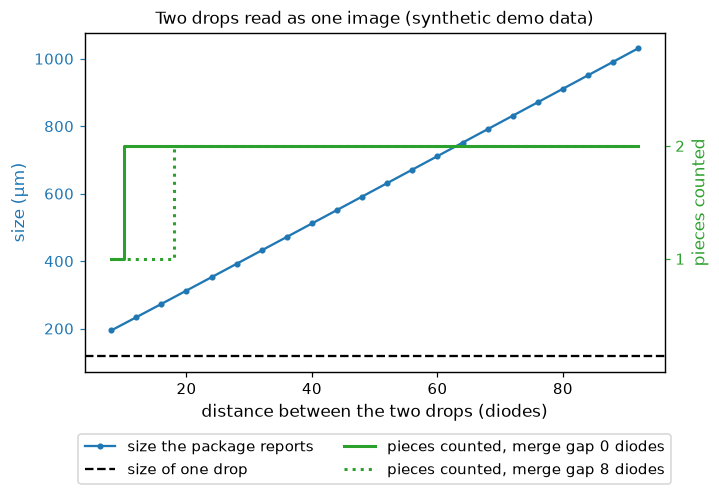

In [4]:
s_all = [r[0] for r in rows]
PIECES = "tab:green"           # second axis: its line, label and ticks share this colour
fig, ax = plt.subplots(figsize=(6.8, 4))
ax.plot(s_all, [r[4] * PX_UM for r in rows], "o-", ms=3, color=_style.KEEP, label="size the package reports")
ax.axhline(single * PX_UM, color=_style.TRUTH, ls="--", label="size of one drop")
ax.set_xlabel("distance between the two drops (diodes)")
ax.set_ylabel("size (µm)", color=_style.KEEP)
ax.tick_params(axis="y", colors=_style.KEEP)
ax2 = ax.twinx()
ax2.step(s_all, [r[2] for r in rows], where="mid", color=PIECES, lw=2, label="pieces counted, merge gap 0 diodes")
ax2.step(s_all, [r[3] for r in rows], where="mid", color=PIECES, ls=":", lw=2, label="pieces counted, merge gap 8 diodes")
ax2.set_ylim(0, 3); ax2.set_yticks([1, 2]); ax2.set_ylabel("pieces counted", color=PIECES)
ax2.tick_params(axis="y", colors=PIECES)
ax.set_title("Two drops read as one image (synthetic demo data)", fontsize=11)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=10)
fig.savefig("examples/figures/two_size.png", dpi=110, bbox_inches="tight")
plt.show()


*Figure 2. Size the package reports (blue, left axis, µm) and the number of pieces counted (green, right axis) as the two synthetic drops move apart. Solid green merges no gap; dotted green merges pieces up to 8 diodes apart. The dashed black line is the size of one drop.*

## 3. Does the package detect two particles?

For the *product*, no: the engine has no two-particle detector, and the counted number of
particles is one per image. The pieces tool is a display and labelling aid for the triage page:
`particle_parts` numbers the pieces so a reviewer can say which one is real, and a
`PIECE_COUNT_CLASSES` count (`one`, `two`, `three_or_more`) can be attached to a verdict
(`triage_context.py`, `triage_server.py`); it changes no computed number. The "two particles"
label is one of the four triage verdicts. No automatic splitter, no minimum-blank-slice rule, and
no rule that rejects such an image has been found in the repository; that suggested edit
exists only as a proposal.

## 4. How often

Not measured yet. One confirmed instance has been found (a real image of
149 slices by 34 diodes sized at 1.499 mm); no rate has been measured. The triage page counts the images its
reviewers label "two particles"; those counts are internal and are not quoted here.

## 5. Check your own data

The test below uses only what the table showed: an image whose engine size is much larger than
its largest piece, with two or more pieces at `gap=0`, is a candidate. It is a screening rule
written for this notebook, not a package function, and it fires on a drop with a stray pixel as
well; rule out the stray case by looking at the piece sizes it prints.

In [5]:
def screen(img, ratio=1.5):
    pieces = piece_groups(img, 0)
    if len(pieces) < 2:
        return None
    size = engine(img)[0]
    biggest = max(engine(p)[0] for p in pieces)
    sizes = sorted(int(p.sum()) for p in pieces)
    return dict(pieces=len(pieces), pixels=sizes, engine_px=size, largest_piece_px=biggest,
                candidate=bool(size > ratio * biggest and sizes[-2] > 2))

demo = {"one drop": disc(12, 20),
        "two drops, s=40": pair(40),
        "drop + stray pixel": disc(12, 20) | (ii == 3) & (jj == 100)}
for name, img in demo.items():
    print(f"{name:20s}", screen(img))

one drop             None
two drops, s=40      {'pieces': 2, 'pixels': [97, 97], 'engine_px': 51.15974481593781, 'largest_piece_px': 11.770329614269007, 'candidate': True}
drop + stray pixel   {'pieces': 2, 'pixels': [1, 97], 'engine_px': 86.70880934886448, 'largest_piece_px': 11.770329614269007, 'candidate': False}


## Data summary
The separation scan of section 3 as a labelled dataset, with units.

In [6]:
import xarray as xr
import pandas as pd

ds = xr.Dataset(
    {"size": ("separation", [r[4] * PX_UM for r in rows], {"units": "um"}),
     "pieces_gap0": ("separation", [r[2] for r in rows], {"units": "1"}),
     "pieces_gap8": ("separation", [r[3] for r in rows], {"units": "1"})},
    coords={"separation": ("separation", [r[0] for r in rows], {"units": "diodes"})},
    attrs={"description": "two synthetic 11-pixel drops in one frame", "units": "given per variable"})
ds

<xarray.Dataset> Size: 704B
Dimensions:      (separation: 22)
Coordinates:
  * separation   (separation) int64 176B 8 12 16 20 24 28 ... 72 76 80 84 88 92
Data variables:
    size         (separation) float64 176B 194.4 233.6 273.1 ... 990.8 1.031e+03
    pieces_gap0  (separation) int64 176B 1 2 2 2 2 2 2 2 2 ... 2 2 2 2 2 2 2 2 2
    pieces_gap8  (separation) int64 176B 1 1 1 2 2 2 2 2 2 ... 2 2 2 2 2 2 2 2 2
Attributes:
    description:  two synthetic 11-pixel drops in one frame
    units:        given per variable

Every fourth separation as a table: size, ratio to one drop, and the reject codes.

In [7]:
df = pd.DataFrame({"centre distance (diodes)": [r[0] for r in rows],
                   "size (um)": [round(r[4] * PX_UM) for r in rows],
                   "ratio to one drop (1)": [round(r[4] / single, 1) for r in rows],
                   "reject, stock limits": [r[5] for r in rows],
                   "reject, ORACLES limits": [r[6] for r in rows]})
df.iloc[::4]

,centre distance (diodes),size (um),ratio to one drop (1),"reject, stock limits","reject, ORACLES limits"
0,8,194,1.7,u,u
4,24,352,3.0,0,0
8,40,512,4.3,0,a
12,56,671,5.7,a,a
16,72,831,7.1,a,a
20,88,991,8.4,a,a


## 6. Defaults

From [the configuration page](../../docs/06-configuration.md#corrections-engine-35-applies-by-default) and the [enhancements page](../../docs/05-enhancements.md).

| | Default | Turn it on / off |
|---|---|---|
| two-particle image in the engine | no detection or split; the image is one particle | none exists |
| `remove_stray_pixels` | library: off; engine-3.5 batch driver: on, and inert for two large pieces | `--stray-pixel off` or config `stray_pixel_fix = false` |
| `piece_groups`, `particle_parts` | triage display only; changes no number | `gap` and `scale` arguments |

## What to try next

- Put the second drop at a different time (shift its slices) and watch where the pair stops
  being one connected shape; the engine's own record scan, which this notebook does not run,
  decides whether a blank slice between them splits the frame.
- Make one drop 3 pixels across and see when `screen` flags it as a stray instead.
- Compare `PIECE_GAP_DIODES` with the `scale="larger"` option of `piece_groups`.
- Back to the start: [12_particle_gallery.ipynb](12_particle_gallery.ipynb), the gallery of what is not a particle.